# InspectAI — PatchCore Anomaly Detection

A patch-based industrial anomaly detector for the MVTec AD `metal_nut` category. We fit only on normal images, validate on held-out normal images, and evaluate the fixed configuration on the official test set.

**Model:** ResNet18 `layer2` + `layer3`, 256×256 inputs, approximate greedy coreset, nearest-neighbor patch scoring. This is a **simplified PatchCore implementation**, not an exact reproduction of the paper.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import json
import time

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.models.feature_extraction import create_feature_extractor

from sklearn.metrics import roc_auc_score, average_precision_score

DATA_DIR = Path("../data/raw/metal_nut").resolve()
SPLIT_FILE = Path("../results/normal_split.json").resolve()
MODELS_DIR = Path("../models").resolve()
RESULTS_DIR = Path("../results").resolve()
FIGURES_DIR = RESULTS_DIR / "figures"
for directory in [MODELS_DIR, RESULTS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 8
NUM_CANDIDATES = 4000
CORESET_SIZE = 800
PROJECTION_DIM = 64
DISTANCE_CHUNK_SIZE = 1024
PIXEL_EVAL_SIZE = 128  # Evaluate masks and heatmaps at a common, documented resolution
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

torch.manual_seed(SEED)
np.random.seed(SEED)

assert DATA_DIR.is_dir(), f"Missing dataset: {DATA_DIR}"
assert SPLIT_FILE.is_file(), f"Missing baseline split: {SPLIT_FILE}"
print("Device:", DEVICE)
print("Dataset:", DATA_DIR)
print("Split:", SPLIT_FILE)

Device: mps
Dataset: /Users/chkhai/Documents/projects/inspectAI/data/raw/metal_nut
Split: /Users/chkhai/Documents/projects/inspectAI/results/normal_split.json


## 2. Reuse the baseline train/validation split

In [2]:
with SPLIT_FILE.open() as f:
    split = json.load(f)

normal_dir = DATA_DIR / "train" / "good"
train_paths = [normal_dir / filename for filename in split["train"]]
val_paths = [normal_dir / filename for filename in split["validation"]]
all_train_paths = sorted(normal_dir.glob("*.png"))

assert len(train_paths) == 176 and len(val_paths) == 44
assert len(all_train_paths) == 220
assert set(train_paths).isdisjoint(val_paths)
assert set(train_paths) | set(val_paths) == set(all_train_paths)
assert all(p.is_file() for p in train_paths + val_paths)

print(f"Development train: {len(train_paths)}")
print(f"Normal validation: {len(val_paths)}")
print(f"Final normal training: {len(all_train_paths)}")

Development train: 176
Normal validation: 44
Final normal training: 220


## 3. Image preprocessing and loaders

In [3]:
preprocess = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class ImagePathsDataset(Dataset):
    def __init__(self, paths):
        self.paths = list(paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            return preprocess(image.convert("RGB"))


def make_loader(paths):
    return DataLoader(ImagePathsDataset(paths), batch_size=BATCH_SIZE,
                      shuffle=False, num_workers=0)

train_loader = make_loader(train_paths)
val_loader = make_loader(val_paths)
full_train_loader = make_loader(all_train_paths)
print("Train batches:", len(train_loader), "Validation batches:", len(val_loader))

Train batches: 22 Validation batches: 6


## 4. Extract spatial CNN features

In [4]:
backbone = resnet18(weights=ResNet18_Weights.DEFAULT)
feature_extractor = create_feature_extractor(
    backbone, return_nodes={"layer2": "layer2", "layer3": "layer3"}
).to(DEVICE).eval()
for parameter in feature_extractor.parameters():
    parameter.requires_grad_(False)

@torch.inference_mode()
def extract_patch_embeddings(images):
    maps = feature_extractor(images.to(DEVICE))
    l2 = F.avg_pool2d(maps["layer2"], kernel_size=3, stride=1, padding=1)
    l3 = F.avg_pool2d(maps["layer3"], kernel_size=3, stride=1, padding=1)
    l3 = F.interpolate(l3, size=l2.shape[-2:], mode="bilinear", align_corners=False)
    return torch.cat([l2, l3], dim=1)

example_batch = next(iter(train_loader))
example_embeddings = extract_patch_embeddings(example_batch)
print("Patch embeddings:", tuple(example_embeddings.shape))
assert tuple(example_embeddings.shape) == (BATCH_SIZE, 384, 32, 32)

Patch embeddings: (8, 384, 32, 32)


## 5. Normal patch bank and coreset

In [5]:
@torch.inference_mode()
def build_patch_bank(loader):
    parts = []
    for images in loader:
        embeddings = extract_patch_embeddings(images)
        patches = embeddings.permute(0, 2, 3, 1).reshape(-1, embeddings.shape[1])
        parts.append(patches.cpu())
    return torch.cat(parts, dim=0)


def select_coreset(bank, num_candidates=NUM_CANDIDATES,
                   coreset_size=CORESET_SIZE, projection_dim=PROJECTION_DIM, seed=SEED):
    assert coreset_size <= num_candidates <= len(bank)
    generator = torch.Generator().manual_seed(seed)
    indices = torch.randperm(len(bank), generator=generator)[:num_candidates]
    candidates = bank[indices]
    projection = torch.randn(candidates.shape[1], projection_dim,
                             generator=generator) / np.sqrt(projection_dim)
    embedded = candidates @ projection
    nearest_sq = torch.full((len(candidates),), float("inf"))
    selected = []
    current = 0
    for _ in range(coreset_size):
        selected.append(current)
        d_sq = (embedded - embedded[current]).square().sum(dim=1)
        nearest_sq = torch.minimum(nearest_sq, d_sq)
        nearest_sq[selected] = -1
        current = int(torch.argmax(nearest_sq))
    return candidates[selected].contiguous()

start = time.perf_counter()
train_patch_bank = build_patch_bank(train_loader)
dev_bank = select_coreset(train_patch_bank)
del train_patch_bank
print("Development coreset:", tuple(dev_bank.shape))
print(f"Construction time: {time.perf_counter() - start:.1f} s")
assert dev_bank.shape == (CORESET_SIZE, 384)

dev_bank_path = MODELS_DIR / "patchcore_dev_bank.pt"
torch.save(dev_bank, dev_bank_path)
print("Saved:", dev_bank_path)

Development coreset: (800, 384)
Construction time: 2.0 s
Saved: /Users/chkhai/Documents/projects/inspectAI/models/patchcore_dev_bank.pt


## 6. Nearest-neighbor anomaly scoring

In [6]:
@torch.inference_mode()
def compute_anomaly_scores(images, bank):
    embeddings = extract_patch_embeddings(images)
    batch_size, channels, height, width = embeddings.shape
    patches = embeddings.permute(0, 2, 3, 1).reshape(-1, channels)
    bank_device = bank.to(DEVICE)
    distances = []
    for chunk in patches.split(DISTANCE_CHUNK_SIZE):
        nearest = torch.cdist(chunk.float(), bank_device.float()).min(dim=1).values
        distances.append(nearest)
    maps = torch.cat(distances).reshape(batch_size, height, width)
    image_scores = maps.flatten(1).max(dim=1).values
    return image_scores.cpu().numpy(), maps.cpu().numpy()

example_scores, example_maps = compute_anomaly_scores(next(iter(val_loader)), dev_bank)
print("Scores:", example_scores.shape, "Maps:", example_maps.shape)
assert example_maps.shape == (BATCH_SIZE, 32, 32)

Scores: (8,) Maps: (8, 32, 32)


## 7. Validate on held-out normal images

In [7]:
def score_loader(loader, bank):
    scores, maps = [], []
    for batch in loader:
        batch_scores, batch_maps = compute_anomaly_scores(batch, bank)
        scores.append(batch_scores)
        maps.append(batch_maps)
    return np.concatenate(scores), np.concatenate(maps)

val_scores, val_maps = score_loader(val_loader, dev_bank)
val_stats = {
    "mean": float(val_scores.mean()),
    "median": float(np.median(val_scores)),
    "p95": float(np.percentile(val_scores, 95)),
    "max": float(val_scores.max()),
}
print("Normal validation images:", len(val_scores))
for key, value in val_stats.items():
    print(f"{key}: {value:.4f}")

Normal validation images: 44
mean: 2.2652
median: 2.2591
p95: 2.3870
max: 2.4549


## 8. Inspect normal-validation heatmaps

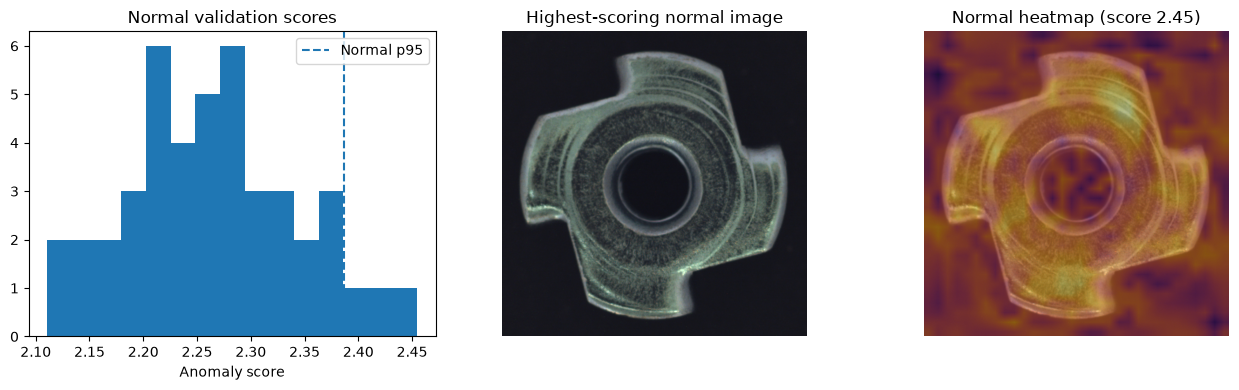

In [8]:
worst_index = int(np.argmax(val_scores))
with Image.open(val_paths[worst_index]) as image:
    image = image.convert("RGB")
    original = np.asarray(image)

fig_val, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].hist(val_scores, bins=15)
axes[0].axvline(val_stats["p95"], linestyle="--", label="Normal p95")
axes[0].set_title("Normal validation scores")
axes[0].set_xlabel("Anomaly score")
axes[0].legend()
axes[1].imshow(original)
axes[1].set_title("Highest-scoring normal image")
axes[2].imshow(original)
axes[2].imshow(val_maps[worst_index], cmap="inferno", alpha=0.5,
               extent=(0, original.shape[1], original.shape[0], 0),
               vmin=0, vmax=float(val_maps.max()), interpolation="bilinear")
axes[2].set_title(f"Normal heatmap (score {val_scores[worst_index]:.2f})")
for ax in axes[1:]:
    ax.axis("off")
fig_val.tight_layout()
val_figure_path = FIGURES_DIR / "patchcore_validation.png"
fig_val.savefig(val_figure_path, dpi=130, bbox_inches="tight")
plt.show()

## 9. Final model: fit on all 220 normal images

In [9]:
start = time.perf_counter()
full_patch_bank = build_patch_bank(full_train_loader)
final_bank = select_coreset(full_patch_bank)
del full_patch_bank
final_bank_path = MODELS_DIR / "patchcore_final_bank.pt"
torch.save(final_bank, final_bank_path)
print("Final memory bank:", tuple(final_bank.shape))
print(f"Final fitting time: {time.perf_counter() - start:.1f} s")
print("Saved:", final_bank_path)

Final memory bank: (800, 384)
Final fitting time: 2.2 s
Saved: /Users/chkhai/Documents/projects/inspectAI/models/patchcore_final_bank.pt


## 10. Prepare the official test set

In [10]:
test_samples = []
for category_dir in sorted((DATA_DIR / "test").iterdir()):
    if not category_dir.is_dir():
        continue
    for image_path in sorted(category_dir.glob("*.png")):
        category = category_dir.name
        mask_path = (DATA_DIR / "ground_truth" / category / f"{image_path.stem}_mask.png"
                     if category != "good" else None)
        if mask_path is not None:
            assert mask_path.is_file(), f"Missing mask: {mask_path}"
        test_samples.append((image_path, int(category != "good"), category, mask_path))

test_paths = [item[0] for item in test_samples]
test_labels = np.array([item[1] for item in test_samples], dtype=np.uint8)
test_categories = np.array([item[2] for item in test_samples])
test_loader = make_loader(test_paths)
assert len(test_paths) == 115 and test_labels.sum() == 93
print("Test images:", len(test_paths), "Anomalous:", test_labels.sum())

Test images: 115 Anomalous: 93


## 11. Final inference and metrics

In [11]:
start = time.perf_counter()
test_scores, test_maps = score_loader(test_loader, final_bank)
inference_seconds = time.perf_counter() - start

# Upsample predicted low-resolution maps to a common pixel evaluation size.
resized_pred_maps = F.interpolate(
    torch.from_numpy(test_maps).unsqueeze(1),
    size=(PIXEL_EVAL_SIZE, PIXEL_EVAL_SIZE),
    mode="bilinear", align_corners=False
).squeeze(1).numpy()

resized_true_masks = []
for _, label, _, mask_path in test_samples:
    if label == 0:
        resized_true_masks.append(np.zeros((PIXEL_EVAL_SIZE, PIXEL_EVAL_SIZE), dtype=np.uint8))
    else:
        with Image.open(mask_path) as mask_image:
            mask_image = mask_image.convert("L").resize(
                (PIXEL_EVAL_SIZE, PIXEL_EVAL_SIZE), resample=Image.Resampling.NEAREST
            )
            resized_true_masks.append((np.asarray(mask_image) > 0).astype(np.uint8))
resized_true_masks = np.stack(resized_true_masks)

image_auroc = roc_auc_score(test_labels, test_scores)
image_ap = average_precision_score(test_labels, test_scores)
pixel_auroc = roc_auc_score(resized_true_masks.ravel(), resized_pred_maps.ravel())
pixel_ap = average_precision_score(resized_true_masks.ravel(), resized_pred_maps.ravel())

category_results = {}
for category in ["scratch", "bent", "color", "flip"]:
    subset = (test_categories == "good") | (test_categories == category)
    category_results[category] = float(roc_auc_score(test_labels[subset], test_scores[subset]))

metrics = {
    "image_auroc": float(image_auroc),
    "image_ap": float(image_ap),
    "pixel_auroc_128": float(pixel_auroc),
    "pixel_ap_128": float(pixel_ap),
    "inference_seconds_total": float(inference_seconds),
    "inference_seconds_per_image": float(inference_seconds / len(test_paths)),
    **{f"image_auroc_{k}": v for k, v in category_results.items()}
}
print("=== PatchCore Results ===")
for name, value in metrics.items():
    print(f"{name}: {value:.4f}")
print("Baseline image AUROC reference: 0.8109")

metrics_file = RESULTS_DIR / "patchcore_metrics.json"
with metrics_file.open("w") as f:
    json.dump(metrics, f, indent=2)
print("Metrics saved locally:", metrics_file)

=== PatchCore Results ===
image_auroc: 0.9834
image_ap: 0.9962
pixel_auroc_128: 0.9749
pixel_ap_128: 0.8359
inference_seconds_total: 1.2388
inference_seconds_per_image: 0.0108
image_auroc_scratch: 0.9723
image_auroc_bent: 0.9964
image_auroc_color: 0.9628
image_auroc_flip: 1.0000
Baseline image AUROC reference: 0.8109
Metrics saved locally: /Users/chkhai/Documents/projects/inspectAI/results/patchcore_metrics.json


## 12. Visualize test predictions

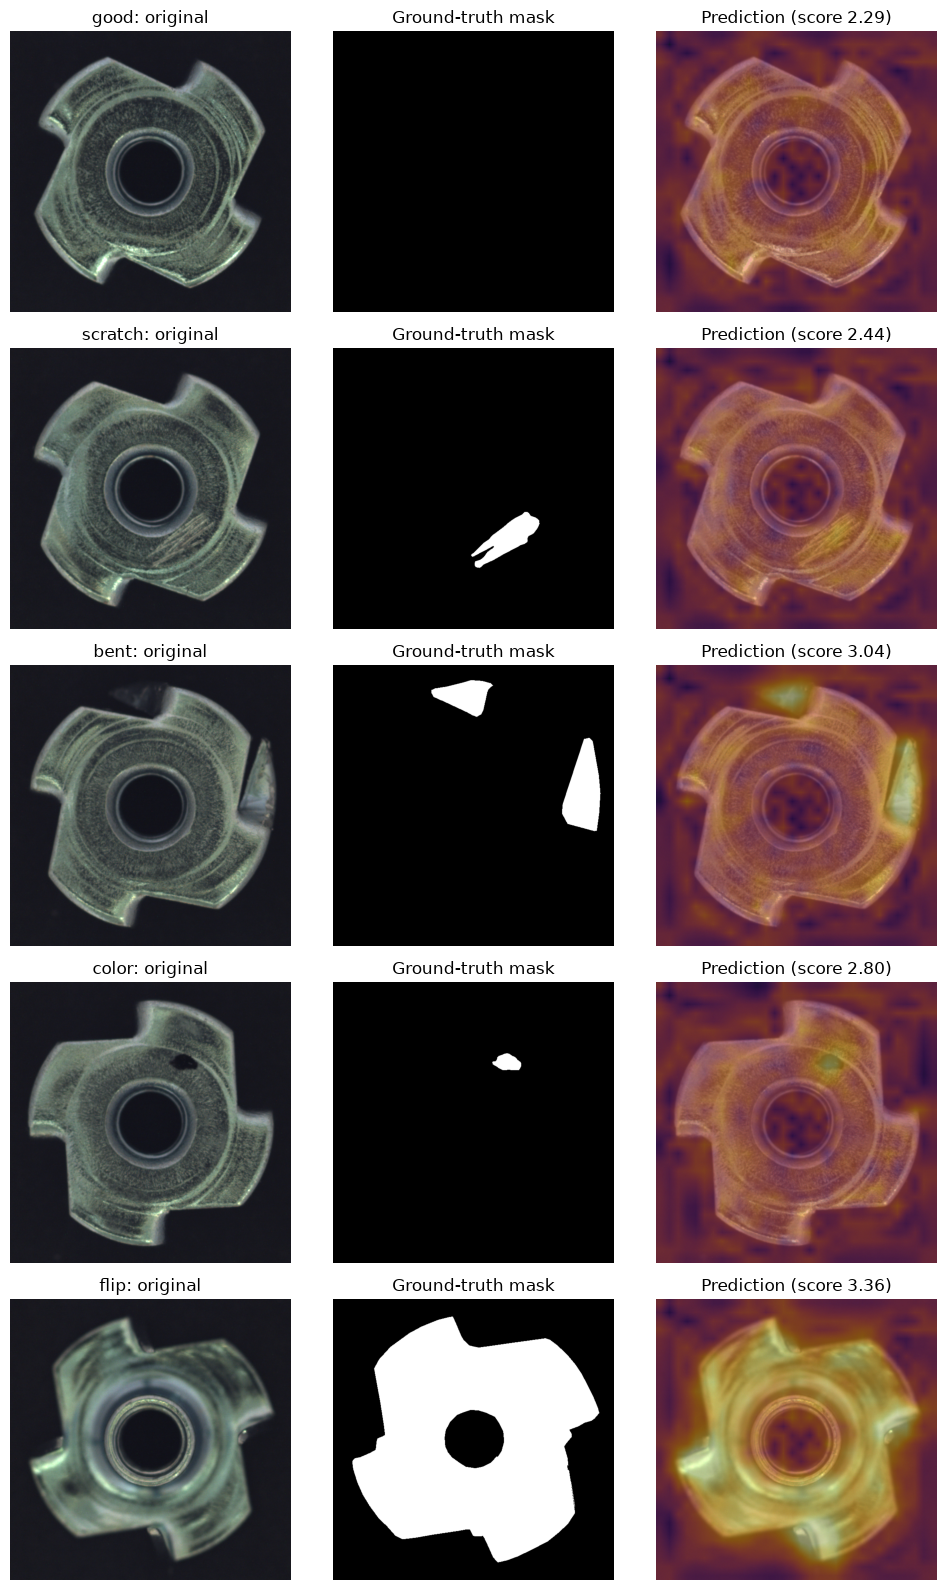

In [12]:
categories_to_show = ["good", "scratch", "bent", "color", "flip"]
example_ids = [int(np.where(test_categories == name)[0][0]) for name in categories_to_show]
fig_test, axes = plt.subplots(len(example_ids), 3, figsize=(10, 16))
map_max = float(np.percentile(test_maps, 99.5))
for row, index in enumerate(example_ids):
    image_path, label, category, mask_path = test_samples[index]
    with Image.open(image_path) as im:
        original = np.asarray(im.convert("RGB"))
    axes[row, 0].imshow(original)
    axes[row, 0].set_title(f"{category}: original")
    if mask_path:
        with Image.open(mask_path) as im:
            mask = np.asarray(im.convert("L"))
    else:
        mask = np.zeros(original.shape[:2], dtype=np.uint8)
    axes[row, 1].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[row, 1].set_title("Ground-truth mask")
    axes[row, 2].imshow(original)
    axes[row, 2].imshow(test_maps[index], cmap="inferno", alpha=0.48,
                        extent=(0, original.shape[1], original.shape[0], 0),
                        vmin=0, vmax=map_max, interpolation="bilinear")
    axes[row, 2].set_title(f"Prediction (score {test_scores[index]:.2f})")
    for ax in axes[row]:
        ax.axis("off")
fig_test.tight_layout()
test_figure_path = FIGURES_DIR / "patchcore_test_examples.png"
fig_test.savefig(test_figure_path, dpi=130, bbox_inches="tight")
plt.show()

## 13. Log completed experiment to DagsHub / MLflow

In [13]:
import dagshub
import mlflow

params = {
    "model": "simplified_patchcore",
    "backbone": "resnet18",
    "feature_layers": "layer2+layer3",
    "input_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "coreset_candidates": NUM_CANDIDATES,
    "coreset_size": CORESET_SIZE,
    "projection_dim": PROJECTION_DIM,
    "train_samples_dev": len(train_paths),
    "normal_validation_samples": len(val_paths),
    "final_train_samples": len(all_train_paths),
    "test_samples": len(test_paths),
    "pixel_evaluation_size": PIXEL_EVAL_SIZE,
    "seed": SEED,
    "image_score_rule": "max_patch_distance",
    "selection_uses_test_set": False,
}

# To skip remote logging temporarily, set this to False.
LOG_TO_DAGSHUB = True

if LOG_TO_DAGSHUB:
    try:
        assert mlflow.active_run() is None, "Close the existing MLflow run first."
        dagshub.init(repo_owner="lchkh23", repo_name="inspectAI", mlflow=True)
        mlflow.set_experiment("metal-nut-anomaly-detection")
        with mlflow.start_run(run_name="patchcore-resnet18-final"):
            mlflow.log_params(params)
            mlflow.log_metrics(metrics)
            mlflow.log_metrics({f"dev_val_{key}_score": value for key, value in val_stats.items()})
            mlflow.log_artifact(str(SPLIT_FILE), artifact_path="splits")
            mlflow.log_artifact(str(metrics_file), artifact_path="results")
            mlflow.log_artifact(str(final_bank_path), artifact_path="models")
            mlflow.log_artifact(str(val_figure_path), artifact_path="figures")
            mlflow.log_artifact(str(test_figure_path), artifact_path="figures")
        print("DagsHub run logged successfully.")
    except Exception as error:
        print("Remote logging failed; all results remain saved locally.")
        print(type(error).__name__, str(error)[:400])
        if mlflow.active_run() is not None:
            try:
                mlflow.end_run(status="FAILED")
            except Exception:
                pass
else:
    print("Remote logging skipped. Local models/figures/metrics are already saved.")

Accessing as lchkh23

Initialized MLflow to track repo "lchkh23/inspectAI"

Repository lchkh23/inspectAI initialized!

🏃 View run patchcore-resnet18-final at: https://dagshub.com/lchkh23/inspectAI.mlflow/#/experiments/1/runs/5d35d1b5b6904dd79cfa0c684955fe37
🧪 View experiment at: https://dagshub.com/lchkh23/inspectAI.mlflow/#/experiments/1
DagsHub run logged successfully.


In [14]:
print("=== PatchCore Results ===")
print(f"Image AUROC: {image_auroc:.4f}")
print(f"Image AP:    {image_ap:.4f}")
print(f"Pixel AUROC: {pixel_auroc:.4f}")
print(f"Pixel AP:    {pixel_ap:.4f}")

=== PatchCore Results ===
Image AUROC: 0.9834
Image AP:    0.9962
Pixel AUROC: 0.9749
Pixel AP:    0.8359


## 14. Summary and limitations

- **Training:** only normal images; the 176/44 split was reused from the baseline; the final memory bank was rebuilt using all 220 normal images.
- **Evaluation:** official 115-image test set, held separate until the fixed configuration was ready.
- **Primary metrics:** image AUROC and pixel AUROC; pixel AP is also important for localized defects.
- **Implementation caveat:** our random-candidate coreset and maximum-patch image scoring simplify original PatchCore. We are not claiming an exact paper reproduction.
- **Resolution caveat:** pixel metrics are evaluated at 128×128 after resizing masks; record this alongside results.
- **Methodology caveat:** we previously viewed baseline results on the official test set; do not use test results to select new PatchCore hyperparameters. Avoid repeated test-driven tuning.

**Next:** Analyze false positives/negatives and compare the locked PatchCore model to the ResNet18 global-feature baseline.